# Comparativa de OCR

En este cuaderno auxiliar se evalúan y comparan distintos modelos para la obtención del texto de las matrículas. Esto permite justificar la elección del OCR utilizado en la tercera parte de la práctica. En esta comparativa, se analizan cinco modelos de distinta complejidad:

- **Tesseract**: OCR clásico simple, ejecución con `pytesseract` 
- **PaddleOCR**: OCR clásico moderno, ejecución con `paddleocr`
- **GLM-OCR**: VLM pequeño especializado en OCR, ejecución con _Ollama_
- **SmolVLM2**: VLM general pequeño (2B), ejecución con `transformers`
- **Qwen3-VL-8B**: VLM general mediano (8B), ejecución con _Ollama_

## Evaluación

Todos los modelos se evalúan en las mismas condiciones:

- **Datos:** recortes de las matrículas, ajustados a la caja anotada de cada una, en el mismo orden y sin ningún preprocesado adicional. Las matrículas ilegibles se evalúan aparte, pues no tienen un texto con el que comparar la lectura.
- **Métricas:** tasa de acierto, CER (_character error rate_) y porcentaje de lecturas con formato de matrícula válido. Sobre las matrículas ilegibles, porcentaje de matrículas inventadas.
- **Tiempo:** tiempo de lectura de cada matrícula. Se realizan lecturas previas de calentamiento, y se excluye el tiempo de carga de los modelos.
- **VLMs:** mismo _prompt_ para todos, temperatura 0 y un máximo de 20 _tokens_ de salida para cortar respuestas largas.

Tras la evaluación de todos los modelos, se han agregado las estadísticas en tablas y en gráficas de _Tensorboard_.

## Índice

1. [Preparación](#1-preparación)
    - [1.1 Configuración](#11-configuración)
    - [1.2 Información del equipo](#12-información-del-equipo)
2. [Conjunto de datos](#2-conjunto-de-datos)
    - [2.1 Anotaciones](#21-anotaciones)
    - [2.2 Recortes de las matrículas](#22-recortes-de-las-matrículas)
3. [Normalización y métricas](#3-normalización-y-métricas)
    - [3.1 Normalización](#31-normalización)
    - [3.2 Métricas](#32-métricas)
4. [Modelos de OCR](#4-modelos-de-ocr)
    - [4.1 Tesseract](#41-tesseract)
    - [4.2 PaddleOCR](#42-paddleocr)
    - [4.3 VLMs con Ollama](#43-vlms-con-ollama)
    - [4.4 SmolVLM2](#44-smolvlm2)
5. [Evaluación de los modelos](#5-evaluación-de-los-modelos)
    - [5.1 Memoria de vídeo](#51-memoria-de-vídeo)
    - [5.2 Generación de métricas](#52-generación-de-métricas)
    - [5.3 Resultados](#53-resultados)
6. [Gráficas](#6-gráficas)
7. [TensorBoard](#7-tensorboard)
8. [Conclusiones](#8-conclusiones)

## 1. Preparación

### 1.1 Configuración

In [1]:
import json
import shutil
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import ollama
import pandas as pd
import pytesseract
import torch
from huggingface_hub import snapshot_download
from PIL import Image
from torch.utils.tensorboard import SummaryWriter
from transformers import AutoModelForImageTextToText, AutoProcessor

from common.det_metrics import sync
from common.ocr import PADDLE_REC_MODEL, OCRModel, PaddleOCRModel
from common.paths import DATASET, ROOT
from common.plate_text import cer, is_valid_plate, normalize
from common.specs import VramMonitor, command_output, save_system_info

Rutas (las compartidas, en [`paths.py`](./common/paths.py)) del _dataset_ de matrículas (con las carpetas `images/` y `annotations/`), de los resultados y de los registros de TensorBoard:

In [2]:
OCR_DIR = ROOT / "ocr"
RESULTS = OCR_DIR / "results"
MODEL_RESULTS = RESULTS / "models"
FIGURES = RESULTS / "figures"
TENSORBOARD = OCR_DIR / "runs"

for d in (MODEL_RESULTS, FIGURES):
    d.mkdir(parents=True, exist_ok=True)

Parámetros de la comparativa:

- `WARMUP`: lecturas de calentamiento, que se realizan antes de empezar a medir el tiempo, para evitar sesgar las estadísticas con un arranque en frío.

In [3]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WARMUP = 5

print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sin GPU)")

device: cuda NVIDIA GeForce RTX 5080


Configuración de cada modelo. Todos los VLMs reciben el mismo _prompt_, salvo GLM-OCR, que está entrenado para responder a su propio _prompt_ de reconocimiento de texto (`Text Recognition:`):

In [4]:
PROMPT = "Read the license plate in this image. Respond with only the plate characters, no other text."
MAX_NEW_TOKENS = 20
VLM_OPTIONS = {"temperature": 0, "num_predict": MAX_NEW_TOKENS}

TESSERACT_CONFIG = "--psm 7 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
GLM_OCR_TAG = "glm-ocr:bf16"
SMOLVLM_ID = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
QWEN_VL_TAG = "qwen3-vl:8b-instruct-q8_0"

### 1.2 Información del equipo

Los tiempos dependen del equipo en el que se miden, por lo que se guarda esta información, junto con los modelos utilizados, en `system_info.json` (ver funciones en [`specs.py`](./common/specs.py)):

In [5]:
PACKAGES = ["torch", "transformers", "paddlepaddle-gpu", "paddlepaddle", "paddleocr", "pytesseract", "ollama", "opencv-python"]
MODELS = {"paddleocr": PADDLE_REC_MODEL, "glm-ocr": GLM_OCR_TAG, "smolvlm2": SMOLVLM_ID, "qwen3-vl-8b": QWEN_VL_TAG}

save_system_info(RESULTS / "system_info.json", PACKAGES,
                 tesseract=str(pytesseract.get_tesseract_version()),
                 ollama=command_output(["ollama", "--version"]),
                 models=MODELS)

{'os': 'Windows-10-10.0.26200-SP0',
 'cpu': 'AMD64 Family 26 Model 68 Stepping 0, AuthenticAMD',
 'cpu_cores': 8,
 'ram_gb': 34.0,
 'python': '3.11.18',
 'gpu': 'NVIDIA GeForce RTX 5080',
 'gpu_driver': '610.88',
 'cuda': '13.0',
 'tesseract': '5.5.3.20260724',
 'ollama': 'ollama version is 0.30.10',
 'models': {'paddleocr': 'PP-OCRv5_server_rec',
  'glm-ocr': 'glm-ocr:bf16',
  'smolvlm2': 'HuggingFaceTB/SmolVLM2-2.2B-Instruct',
  'qwen3-vl-8b': 'qwen3-vl:8b-instruct-q8_0'},
 'packages': {'torch': '2.14.1+cu130',
  'transformers': '5.22.1',
  'paddlepaddle-gpu': '3.4.0',
  'paddlepaddle': None,
  'paddleocr': '3.7.0',
  'pytesseract': '0.3.13',
  'ollama': '0.6.3',
  'opencv-python': '4.10.0.84'}}

## 2. Conjunto de datos

### 2.1 Anotaciones

Se utiliza el conjunto de datos de matrículas creado para la asignatura, que se encuentra en `../dataset/`. Cada imagen de `images/` tiene en `annotations/` un JSON con el mismo nombre, que contiene una lista con todas sus matrículas:

```json
[{"rectangle": [x_center, y_center, width, height], "plate": "0000AAA"}, ...]
```

- `rectangle`: caja de la matrícula en formato YOLO, relativa al tamaño de la imagen.
- `plate`: texto de la matrícula, o `"None"` si no es legible.

Las matrículas legibles y las ilegibles se separan en dos listas, para ser analizadas separadamente.

### 2.2 Recortes de las matrículas

Las _bounding boxes_ se deben pasar a píxeles, para poder recortar las matrículas sobre la imagen original:

In [6]:
def bbox_to_pixels(rectangle, width, height):
    cx, cy, w, h = rectangle
    return (round((cx - w / 2) * width), round((cy - h / 2) * height),
            round((cx + w / 2) * width), round((cy + h / 2) * height))

Todos los modelos leen exactamente los mismos recortes. Cada recorte se obtiene de la imagen, ajustado a la _bounding box_ de la matrícula. Se descartan los recortes no válidos, que no van a poder generar una buena lectura (`MIN_CROP_SIDE`):

In [7]:
MIN_CROP_SIDE = 4

def crop_plate(image, box):
    x1, y1, x2, y2 = (int(v) for v in box)
    height, width = image.shape[:2]
    return image[max(0, y1):min(height, y2), max(0, x1):min(width, x2)]

def is_valid_crop(crop):
    return min(crop.shape[:2]) >= MIN_CROP_SIDE

Para cada imagen, se lee su JSON y se recortan todas sus matrículas. Los recortes se cachean en memoria antes de medir, para aislar la lectura de disco del tiempo de cada modelo. Se copian los recortes, para no mantener en memoria la imagen completa. Las matrículas legibles y las ilegibles se separan en dos listas:

In [8]:
def image_plates(image_path):
    image = cv2.imread(str(image_path))
    height, width = image.shape[:2]
    annotations = json.load(open(DATASET / "annotations" / f"{image_path.stem}.json", encoding="utf-8"))
    return [{"image": image_path.name, "crop": crop_plate(image, bbox_to_pixels(a["rectangle"], width, height)).copy(), "ann": a["plate"]}
            for a in annotations]


def load_plates():
    plates = [plate for image_path in sorted((DATASET / "images").iterdir()) for plate in image_plates(image_path)]
    valid = [plate for plate in plates if is_valid_crop(plate["crop"])]
    print(f"{len(plates) - len(valid)} recortes descartados por tamaño no válido")
    return [plate for plate in valid if plate["ann"] != "None"], [plate for plate in valid if plate["ann"] == "None"]

In [9]:
PLATES, ILLEGIBLE_PLATES = load_plates()
print(f"{len(PLATES)} matrículas legibles, {len(ILLEGIBLE_PLATES)} ilegibles")

151 recortes descartados por tamaño no válido
3196 matrículas legibles, 1285 ilegibles


Por ejemplo, estos son los recortes para las 5 primeras matrículas:

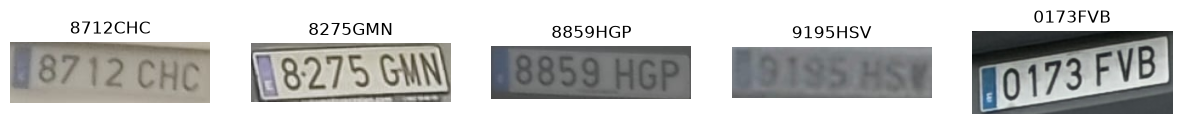

In [10]:
def show_plates(plates, n=5):
    plt.figure(figsize=(3 * n, 2))
    for i, plate in enumerate(plates[:n]):
        plt.subplot(1, n, i + 1)
        plt.imshow(cv2.cvtColor(plate["crop"], cv2.COLOR_BGR2RGB))
        plt.title(plate["ann"])
        plt.axis("off")
    plt.show()


show_plates(PLATES)

## 3. Normalización y métricas

### 3.1 Normalización

Antes de comparar una lectura con su anotación, se aplica la misma normalización a ambas:

1. Se elimina la introducción que podría añadir un VLM a la respuesta (como `The license plate is ...`).
2. Se pasa el texto a mayúsculas y se eliminan los espacios, guiones, puntos y cualquier otro carácter no alfanumérico.

Estas funciones (`normalize`, `cer` e `is_valid_plate`) están en [`plate_text.py`](./common/plate_text.py), compartido con la práctica final.

### 3.2 Métricas

- **Tasa de acierto:** porcentaje de matrículas cuya lectura coincide exactamente con la anotación.
- **CER:** _Character Error Rate_ (`cer`), la distancia de edición entre la lectura y la anotación dividida por la longitud de la anotación, que permite analizar lecturas parcialmente correctas.

Las lecturas deben seguir el formato de una matrícula española, tanto actual (`1234BCD`) como antiguas (`GC 1234 AB`). Esto permite descartar lecturas inviables, que no cumplan estos patrones (`is_valid_plate`).

Además, se calculan una serie de estadísticas que permiten analizar las métricas de tiempo en las lecturas:

In [11]:
def latency_stats(latencies_ms):
    ms = np.asarray(latencies_ms)
    return {"latency_mean_ms": ms.mean(),
            "latency_std_ms": ms.std(),
            "latency_median_ms": np.median(ms),
            "latency_p95_ms": np.percentile(ms, 95),
            "latency_min_ms": ms.min(),
            "latency_max_ms": ms.max(),
            "plates_per_s": 1000 / ms.mean()}

## 4. Modelos de OCR

Todos los modelos reciben un recorte BGR y devuelven el texto leído, sin normalizar. Además, se separan las distintas fases de cada modelo, para poder medirlas por separado:

- `prefetch`: descarga el modelo.
- `load`: carga el modelo en memoria.
- `read`: lee el contenido de una matrícula.
- `close`: libera la memoria.

Es por ello que se hace una clase base `OCRModel` ([`ocr.py`](./common/ocr.py)), para uniformizar los estudios de los distintos modelos.

### 4.1 Tesseract

Tesseract es el OCR clásico de referencia. Se configura para leer una única línea de texto (`--psm 7`) y limitando los caracteres posibles a letras mayúsculas y cifras.

> **Nota:** `pytesseract` ejecuta el programa de Tesseract, que debe estar instalado y en el `PATH` del sistema. Es también por esto que no se incluye ni `prefetch` ni `load`.

In [12]:
class TesseractOCR(OCRModel):
    def __init__(self):
        super().__init__("tesseract")

    def read(self, crop_bgr):
        return pytesseract.image_to_string(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB), config=TESSERACT_CONFIG)

### 4.2 PaddleOCR

Solo se utiliza el módulo de reconocimiento de texto de `PaddleOCR`, pues no se necesita detectar dónde está el texto. Su clase, `PaddleOCRModel`, está también en [`ocr.py`](./common/ocr.py), para poder reutilizarlo en el modelo final (_sentimos el spoiler..._).

### 4.3 VLMs con Ollama

`GLM-OCR` y `Qwen3-VL` se ejecutan con Ollama, que requiere una interacción diferente:

- **Carga:** lanzar una petición vacía y solicitar que se mantenga el modelo en memoria (`keep_alive=-1`).
- **Lectura:** envío de la imagen en formato PNG, y guardado del tiempo sin incluir la comunicación con el servidor.
- **Cierre:** eliminar el modelo de la memoria (`keep_alive=0`).

In [13]:
def to_png(crop_bgr):
    return cv2.imencode(".png", crop_bgr)[1].tobytes()


class OllamaVLM(OCRModel):
    def __init__(self, name, tag, prompt=PROMPT):
        super().__init__(name)
        self.tag = tag
        self.prompt = prompt

    def prefetch(self):
        ollama.pull(self.tag)

    def load(self):
        ollama.generate(model=self.tag, prompt="", keep_alive=-1)

    def read(self, crop_bgr):
        message = {"role": "user", "content": self.prompt, "images": [to_png(crop_bgr)]}
        response = ollama.chat(model=self.tag, messages=[message], options=VLM_OPTIONS, keep_alive=-1)
        self.info = {"ollama_total_ms": (response.total_duration or 0) * 1e-6,
                     "ollama_eval_ms": (response.eval_duration or 0) * 1e-6}
        return response.message.content

    def close(self):
        ollama.generate(model=self.tag, prompt="", keep_alive=0)
        super().close()

### 4.4 SmolVLM2

SmolVLM2 se ejecuta con `transformers`. La respuesta del modelo incluye también el _prompt_, por lo que solo se tienen en cuenta los _tokens_ nuevos:

In [14]:
class SmolVLM(OCRModel):
    def __init__(self):
        super().__init__("smolvlm2")
        self.processor = None

    def prefetch(self):
        snapshot_download(SMOLVLM_ID)

    def load(self):
        self.processor = AutoProcessor.from_pretrained(SMOLVLM_ID)
        self.model = AutoModelForImageTextToText.from_pretrained(SMOLVLM_ID, torch_dtype=torch.bfloat16).to(DEVICE)

    def read(self, crop_bgr):
        image = Image.fromarray(cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB))
        messages = [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": PROMPT}]}]
        inputs = self.processor.apply_chat_template(messages, add_generation_prompt=True, tokenize=True,
                                                    return_dict=True, return_tensors="pt").to(DEVICE, dtype=torch.bfloat16)

        generated = self.model.generate(**inputs, do_sample=False, max_new_tokens=MAX_NEW_TOKENS)
        new_tokens = generated[:, inputs["input_ids"].shape[1]:]
        return self.processor.batch_decode(new_tokens, skip_special_tokens=True)[0]

    def close(self):
        self.processor = None
        super().close()

## 5. Evaluación de los modelos

Antes de medir y evaluar los modelos, se deben descargar. Si un modelo ya se ha medido, se reutilizan sus resultados, a no ser que se indique `FORCE = True`:

In [15]:
OCR_MODELS = [
    TesseractOCR(),
    PaddleOCRModel(),
    OllamaVLM("glm-ocr", GLM_OCR_TAG, prompt="Text Recognition:"),
    SmolVLM(),
    OllamaVLM("qwen3-vl-8b", QWEN_VL_TAG),
]
FORCE = False

for model in OCR_MODELS:
    model.prefetch()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

### 5.1 Memoria de vídeo

Los modelos se ejecutan con tres librerías distintas, y los de Ollama lo hacen en un proceso aparte, por lo que la memoria de la GPU no se puede medir desde PyTorch. Para medirla equitativamente en todos, se consulta `nvidia-smi` periódicamente (`VramMonitor`, en [`specs.py`](./common/specs.py)) mientras el modelo se carga y lee las matrículas, y se guarda el máximo, restando la memoria que ya estaba ocupada antes de empezar:

### 5.2 Generación de métricas

Para cada matrícula, se mide únicamente la llamada a `read`. Se debe llamar a `cuda.synchronize()` (`sync`, de [`det_metrics.py`](./common/det_metrics.py)) porque la GPU trabaja de forma asíncrona:

In [16]:
def timed_read(model, crop):
    sync()
    t0 = time.perf_counter()
    raw = model.read(crop)
    sync()
    return raw, 1000 * (time.perf_counter() - t0)

Se calculan distintas métricas para matrículas legibles e ilegibles, que después se resumen en una fila por modelo:

1. `read_legible`: en matrículas legibles, se calculan las métricas tradicionales.
2. `read_illegible`: en las matrículas ilegibles, solo se comprueba si la lectura tiene formato válido, para verificar que el modelo no inventa matrículas.
3. `summarize`: resume las lecturas de cada modelo en una única fila. El tiempo se calcula solo sobre las matrículas legibles.

In [17]:
def read_legible(model, plate):
    raw, latency_ms = timed_read(model, plate["crop"])
    pred, ann = normalize(raw), normalize(plate["ann"])
    return {"model": model.name, "image": plate["image"], "ann": ann, "raw_pred": raw, "pred": pred,
            "correct": pred == ann, "cer": cer(pred, ann), "format_valid": is_valid_plate(pred),
            "latency_ms": latency_ms, **model.info}

In [18]:
def read_illegible(model, plate):
    raw, latency_ms = timed_read(model, plate["crop"])
    pred = normalize(raw)
    return {"model": model.name, "image": plate["image"], "raw_pred": raw, "pred": pred,
            "invented": is_valid_plate(pred), "latency_ms": latency_ms, **model.info}

In [19]:
def summarize(model, rows, illegible_rows, load_s, peak_vram_mb):
    df = pd.DataFrame(rows)
    invented = pd.DataFrame(illegible_rows, columns=["invented"]).invented
    return {"model": model.name, "n_plates": len(df), "n_illegible": len(invented),
            "accuracy": df.correct.mean(), "cer": df.cer.mean(), "format_valid": df.format_valid.mean(),
            "invented_rate": invented.mean(), **latency_stats(df.latency_ms),
            "load_s": load_s, "peak_vram_mb": peak_vram_mb}

Cada modelo se carga, lleva a cabo una serie de lecturas de `WARMUP`, lee todas las matrículas y se liberan los recursos asociados a él. El resumen de cada modelo se guarda en `results/models/`:

In [20]:
def evaluate(model, legible, illegible):
    with VramMonitor() as vram:
        t0 = time.perf_counter()
        model.load()
        load_s = time.perf_counter() - t0
        for plate in legible[:WARMUP]:
            model.read(plate["crop"])
        legible_rows = [read_legible(model, plate) for plate in legible]
        illegible_rows = [read_illegible(model, plate) for plate in illegible]
    model.close()
    return legible_rows, illegible_rows, summarize(model, legible_rows, illegible_rows, load_s, vram.peak_mb)

In [21]:
def load_or_measure(model, legible, illegible, force=False):
    path = MODEL_RESULTS / f"{model.name}.json"
    if path.exists() and not force:
        return json.load(open(path))
    legible_rows, illegible_rows, summary = evaluate(model, legible, illegible)
    pd.DataFrame(legible_rows).to_csv(MODEL_RESULTS / f"{model.name}.csv", index=False)
    pd.DataFrame(illegible_rows).to_csv(MODEL_RESULTS / f"{model.name}_illegible.csv", index=False)
    json.dump(summary, open(path, "w"), indent=1)
    return summary


def print_summary(s):
    print(f"{s['model']:12s} acierto={s['accuracy']:.3f}  CER={s['cer']:.3f}  formato={s['format_valid']:.3f}  inventadas={s['invented_rate']:.3f}  "
          f"tiempo={s['latency_mean_ms']:.1f} ms  carga={s['load_s']:.1f} s  VRAM={s['peak_vram_mb']} MB", flush=True)

### 5.3 Resultados

Resultados de todos los modelos, que se juntan en `summary.csv` (una fila por modelo), `results.csv` (una fila por lectura de matrícula legible) y `results_illegible.csv` (una fila por lectura de matrícula ilegible):

In [22]:
summaries = []
for model in OCR_MODELS:
    s = load_or_measure(model, PLATES, ILLEGIBLE_PLATES, FORCE)
    summaries.append(s)
    print_summary(s)

summary = pd.DataFrame(summaries)
summary.to_csv(RESULTS / "summary.csv", index=False)
summary[["model", "accuracy", "cer", "format_valid", "invented_rate", "latency_mean_ms", "latency_p95_ms",
         "plates_per_s", "load_s", "peak_vram_mb"]].round(3)

tesseract    acierto=0.106  CER=0.529  formato=0.134  inventadas=0.012  tiempo=78.9 ms  carga=0.0 s  VRAM=232 MB


paddleocr    acierto=0.782  CER=0.116  formato=0.817  inventadas=0.043  tiempo=7.7 ms  carga=2.0 s  VRAM=471 MB


glm-ocr      acierto=0.608  CER=0.182  formato=0.656  inventadas=0.072  tiempo=98.4 ms  carga=2.9 s  VRAM=3674 MB


smolvlm2     acierto=0.773  CER=0.105  formato=0.860  inventadas=0.050  tiempo=234.0 ms  carga=7.6 s  VRAM=5316 MB


qwen3-vl-8b  acierto=0.743  CER=0.137  formato=0.822  inventadas=0.050  tiempo=601.3 ms  carga=5.7 s  VRAM=10722 MB


,model,accuracy,cer,format_valid,invented_rate,latency_mean_ms,latency_p95_ms,plates_per_s,load_s,peak_vram_mb
0,tesseract,0.106,0.529,0.134,0.012,78.862,108.158,12.680,0.000,232
1,paddleocr,0.782,0.116,0.817,0.043,7.652,11.014,130.689,1.974,471
2,glm-ocr,0.608,0.182,0.656,0.072,98.438,128.036,10.159,2.881,3674
3,smolvlm2,0.773,0.105,0.860,0.050,234.048,342.373,4.273,7.561,5316
4,qwen3-vl-8b,0.743,0.137,0.822,0.050,601.267,619.424,1.663,5.708,10722


In [23]:
results = pd.concat([pd.read_csv(MODEL_RESULTS / f"{m.name}.csv", keep_default_na=False) for m in OCR_MODELS], ignore_index=True)
results.to_csv(RESULTS / "results.csv", index=False)

results_illegible = pd.concat([pd.read_csv(MODEL_RESULTS / f"{m.name}_illegible.csv", keep_default_na=False) for m in OCR_MODELS], ignore_index=True)
results_illegible.to_csv(RESULTS / "results_illegible.csv", index=False)

## 6. Gráficas

Las gráficas se guardan como PNG en `results/figures/`, para incluirlas en el README. Cada modelo tiene siempre el mismo color, y su nombre aparece siempre junto a su barra o punto:

In [24]:
PALETTE = ["#0000ff", "#ff0000", "#00ff00", "#ffAA00", "#9900ff"]
MODEL_COLORS = {model.name: color for model, color in zip(OCR_MODELS, PALETTE)}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"


def style_axes(ax, title, ylabel):
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED)


def bar_chart(ax, values, errors=None, labels=True):
    bars = ax.bar(values.index, values, yerr=errors, width=0.6, capsize=4, error_kw={"ecolor": MUTED},
                  color=[MODEL_COLORS[name] for name in values.index])
    if labels:
        ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=3, color=INK)

Tasa de acierto, CER y matrículas inventadas de cada modelo:

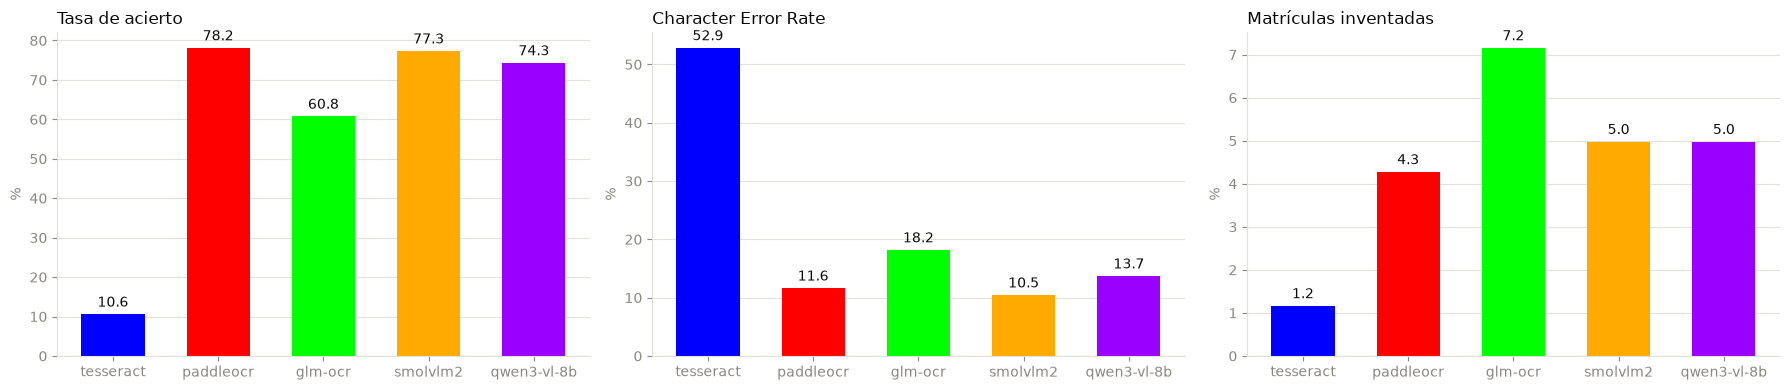

In [25]:
s = summary.set_index("model")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
bar_chart(axes[0], 100 * s.accuracy)
style_axes(axes[0], "Tasa de acierto", "%")
bar_chart(axes[1], 100 * s.cer)
style_axes(axes[1], "Character Error Rate", "%")
bar_chart(axes[2], 100 * s.invented_rate)
style_axes(axes[2], "Matrículas inventadas", "%")
plt.tight_layout()
plt.savefig(FIGURES / "accuracy.png", dpi=150)
plt.show()

Tasa de acierto frente al tiempo de lectura por matrícula:

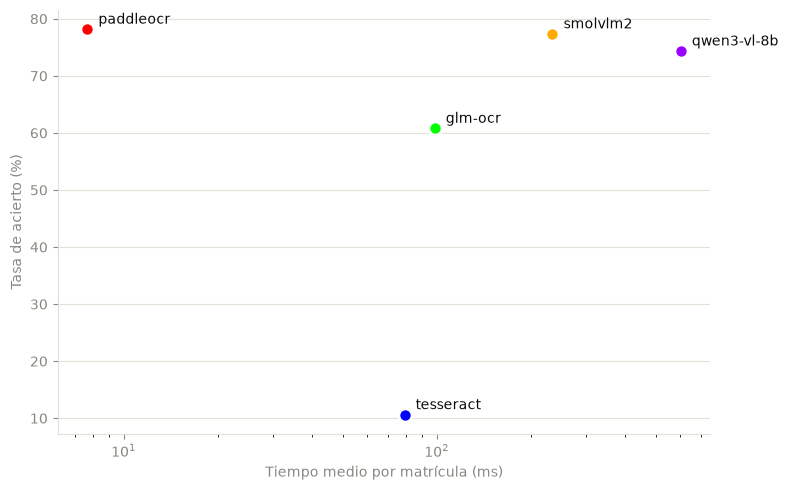

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, row in s.iterrows():
    ax.scatter(row.latency_mean_ms, 100 * row.accuracy, s=90, color=MODEL_COLORS[name], edgecolors="white", linewidths=2, zorder=3)
    ax.annotate(name, (row.latency_mean_ms, 100 * row.accuracy), xytext=(8, 4), textcoords="offset points", color=INK)
ax.set_xscale("log")
ax.set_xlabel("Tiempo medio por matrícula (ms)", color=MUTED)
style_axes(ax, "", "Tasa de acierto (%)")
plt.tight_layout()
plt.savefig(FIGURES / "pareto.png", dpi=150)
plt.show()

## 7. TensorBoard

Se registra en TensorBoard un _run_ por modelo (`runs/<modelo>`), con:

- Latencia de la lectura.
- Comparativa entre anotación y predicción realizada.
- Recortes mal leídos (`errors`).
- Resumen de sus métricas (tabla en HPARAMS).

In [27]:
def log_tensorboard(rows, summary, plates):
    with SummaryWriter(TENSORBOARD / summary["model"]) as w:
        for i, (row, plate) in enumerate(zip(rows, plates)):
            w.add_scalar("latency_ms", row["latency_ms"], i)
            w.add_text("pred", f"Ann: {row['ann']} | Pred: {row['pred']}", i)
            if not row["correct"]:
                w.add_image("errors", cv2.cvtColor(plate["crop"], cv2.COLOR_BGR2RGB), i, dataformats="HWC")
        metrics = {f"hp/{k}": summary[k] for k in ("accuracy", "cer", "format_valid", "invented_rate", "latency_mean_ms")}
        w.add_hparams({"model": summary["model"]}, metrics, run_name=".")

In [28]:
shutil.rmtree(TENSORBOARD, ignore_errors=True)
for _, s in summary.iterrows():
    log_tensorboard(results[results.model == s.model].to_dict("records"), s, PLATES)

## 8. Conclusiones

Se elige PaddleOCR como modelo para el módulo OCR del modelo final, por estos motivos:

- **Acierto:** PaddleOCR (78,2 %) y SmolVLM2 (77,3 %) son los que más matrículas leen correctamente, seguidos de Qwen3-VL (74,3 %) y GLM-OCR (60,8 %). Tesseract apenas acierta (10,6 %), probablemente porque está pensado para texto _estándar_ de documentos.
- **Tiempo y memoria:** PaddleOCR lee una matrícula en 7,7 ms y usa 471 MB de GPU. SmolVLM2 tarda unas 31 veces más (234 ms, 5,3 GB) y Qwen3-VL unas 79 veces más (601 ms, 10,7 GB), sin acertar más. Solo PaddleOCR (130 matrículas por segundo) es viable para leer matrículas en tiempo real en un vídeo.
- **Tamaño:** Qwen3-VL (8B) no supera a SmolVLM2 (2B), y GLM-OCR, especializado en OCR, queda por debajo de ambos. PaddleOCR, que ni siquiera es un modelo de lenguaje, proporciona mejores resultados que todos ellos. Para esta tarea, un reconocedor de texto pequeño funciona mejor que un modelo de lenguaje general.
- **Calidad de la lectura:** SmolVLM2 tiene el menor CER (10,5 %) y más lecturas con formato válido (86 %) que PaddleOCR (11,6 % y 81,7 %). En este caso, la diferencia no compensa el sobrecoste del VLM frente al OCR clásico.
- **Matrículas inventadas:** el porcentaje de lecturas válidas en matrículas ilegibles se encuentra entre el 4 % y el 7 % en todos los modelos salvo Tesseract (1,2 %), porque directamente no lee casi nunca nada con formato válido. PaddleOCR inventa el 4,3 %, que es una métrica decente, pero tampoco convendría fiarse a ciegas de una sola lectura. En el modelo final, se considerará añadir criterios adicionales, como leer varias veces y elegir el número de matrícula más repetido.